In [3]:
# ПР15. Тематическое моделирование текстов вакансий
# Полностью ручной подход: частотный анализ, биграммы, выделение тем

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

# загружаем данные
df = pd.read_csv('data/jobs.csv')
print(f"Загружено {len(df)} вакансий")

# выбираем профессию для анализа
top_titles = df['title'].value_counts()
print(f"\nТоп-5 профессий:\n{top_titles.head(5)}")

selected_title = top_titles.index[1]
print(f"\nВыбрана профессия: {selected_title}")

df_selected = df[df['title'] == selected_title].copy()
print(f"Отобрано {len(df_selected)} вакансий")

Загружено 11097 вакансий

Топ-5 профессий:
title
Системный администратор    73
Офис-менеджер              65
Кладовщик                  56
Товаровед                  49
Юрист                      39
Name: count, dtype: int64

Выбрана профессия: Офис-менеджер
Отобрано 65 вакансий


In [6]:
# функция очистки текста
def clean_text(text):
    if pd.isna(text):
        return ""
    text = str(text)
    text = text.lower()
    text = re.sub(r'[^а-яa-z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

# русские стоп-слова
stopwords = set([
    'и', 'в', 'во', 'не', 'что', 'на', 'гк', 'я', 'с', 'со', 'как', 'а', 'то', 'все', 'она', 'так', 'его', 'но',
    'да', 'ты', 'к', 'у', 'же', 'вы', 'за', 'бы', 'по', 'только', 'ее', 'мне', 'было', 'вот', 'от', 'меня',
    'еще', 'нет', 'о', 'из', 'ему', 'теперь', 'когда', 'даже', 'ну', 'ли', 'если', 'уже', 'или', 'ни', 'быть',
    'был', 'него', 'до', 'вас', 'опять', 'уж', 'вам', 'ведь', 'там', 'потом', 'себя', 'ничего', 'ей', 'может',
    'они', 'тут', 'где', 'есть', 'надо', 'ней', 'для', 'мы', 'тебя', 'их', 'чем', 'была', 'сам', 'чтоб', 'без',
    'будто', 'чего', 'раз', 'тоже', 'себе', 'под', 'будет', 'ж', 'тогда', 'кто', 'этот', 'того', 'потому',
    'этого', 'какой', 'совсем', 'ним', 'здесь', 'этом', 'один', 'почти', 'мой', 'тем', 'чтобы', 'нее', 'сейчас',
    'были', 'куда', 'зачем', 'всех', 'никогда', 'можно', 'при', 'наконец', 'два', 'об', 'другой', 'хоть', 'после',
    'над', 'больше', 'тот', 'через', 'эти', 'нас', 'про', 'всего', 'них', 'какая', 'много', 'три', 'эту', 'моя',
    'впрочем', 'хорошо', 'свою', 'этой', 'перед', 'иногда', 'лучше', 'чуть', 'том', 'нельзя', 'такой', 'им',
    'более', 'всегда', 'конечно', 'всю', 'между', 'работа', 'компания', 'сотрудник', 'вакансия', 'должность',
    'офис', 'график', 'оформление', 'высшее', 'опыт', 'знание', 'умение', 'навык'
])

# очищаем тексты
df_selected['description_clean'] = df_selected['description'].apply(clean_text)
df_selected['key_skills_clean'] = df_selected['key_skills'].apply(clean_text)
df_selected['full_text'] = df_selected['description_clean'] + ' ' + df_selected['key_skills_clean']

print("Пример очищенного текста:")
print(df_selected['full_text'].iloc[0][:500])

Пример очищенного текста:
менеджер по продажам гк содби с 2008 г на рынке основной вид деятельности компании продажа автоматических ворот рольставни шлагбаумы в связи с увеличением сбыта и развитием компании ищем менеджера по продажам требования успешный опыт работы в продажах не менее 1 года отличные коммуникативные навыки пунктуальность грамотная речь целеустремленность нацеленность на результат обязанности работа со входящими заявками активная работа с действующей клиентской базой составление коммерческих предложений 


In [7]:
# функция токенизации
def tokenize(text, min_len=3):
    tokens = text.split()
    tokens = [t for t in tokens if len(t) >= min_len and t not in stopwords]
    return tokens

# токенизируем все тексты
df_selected['tokens'] = df_selected['full_text'].apply(tokenize)

# общий список всех токенов
all_tokens = []
for tokens in df_selected['tokens']:
    all_tokens.extend(tokens)

# частотный анализ
freq = Counter(all_tokens)
print("ТОП-30 САМЫХ ЧАСТЫХ СЛОВ:")
for word, count in freq.most_common(30):
    print(f"  {word}: {count}")

ТОП-30 САМЫХ ЧАСТЫХ СЛОВ:
  работы: 118
  компании: 76
  офиса: 75
  ведение: 65
  требования: 57
  обязанности: 55
  условия: 53
  обеспечение: 53
  организация: 53
  речь: 49
  грамотная: 48
  пользователь: 47
  прием: 42
  документов: 42
  руководителя: 39
  жизнедеятельности: 35
  контроль: 35
  работать: 35
  выполнение: 31
  клиентов: 30
  поручений: 30
  звонков: 29
  документооборот: 29
  распределение: 28
  корреспонденции: 28
  договоров: 26
  официальное: 24
  заказ: 23
  excel: 23
  документации: 23


In [8]:
# функция для поиска биграмм (соседних слов)
def find_bigrams(tokens_list):
    bigrams = []
    for tokens in tokens_list:
        for i in range(len(tokens) - 1):
            if len(tokens[i]) > 2 and len(tokens[i+1]) > 2:
                bigrams.append(f"{tokens[i]} {tokens[i+1]}")
    return Counter(bigrams)

# находим биграммы
bigrams = find_bigrams(df_selected['tokens'].tolist())
print("\nТОП-20 БИГРАММ (словосочетаний):")
for bigram, count in bigrams.most_common(20):
    print(f"  {bigram}: {count}")


ТОП-20 БИГРАММ (словосочетаний):
  жизнедеятельности офиса: 34
  обеспечение жизнедеятельности: 33
  грамотная речь: 30
  уверенный пользователь: 22
  поручений руководителя: 20
  официальное трудоустройство: 20
  заработная плата: 17
  word excel: 17
  прием распределение: 17
  грамотная устная: 14
  устная письменная: 14
  письменная речь: 14
  выполнение поручений: 14
  входящей исходящей: 13
  деловая переписка: 13
  консультирование клиентов: 12
  руководителя требования: 12
  исходящей корреспонденции: 11
  рабочий день: 11
  входящих звонков: 11


In [9]:
# ручное выделение тем на основе частотных слов и биграмм
print("\n" + "="*60)
print("ВЫДЕЛЕНИЕ ТЕМ НА ОСНОВЕ ЧАСТОТНОГО АНАЛИЗА")
print("="*60)

# группируем слова по темам
topics = {
    'Тема 1: Технические навыки и технологии': [
        'программирование', 'разработка', 'код', 'алгоритм', 'отладка',
        'python', 'java', 'sql', 'база', 'данные', 'фреймворк', 'библиотека',
        'инструмент', 'среда', 'разработки'
    ],
    'Тема 2: Управление и организация': [
        'управление', 'руководство', 'команда', 'проект', 'план', 'задача',
        'контроль', 'отчет', 'документация', 'организация', 'координация'
    ],
    'Тема 3: Анализ и исследования': [
        'анализ', 'исследование', 'данные', 'метрика', 'статистика',
        'отчетность', 'дашборд', 'визуализация', 'прогноз', 'модель'
    ],
    'Тема 4: Коммуникации и клиенты': [
        'клиент', 'переговоры', 'презентация', 'консультация', 'поддержка',
        'общение', 'коммуникация', 'сервис', 'обслуживание', 'встреча'
    ],
    'Тема 5: Процессы и качество': [
        'тестирование', 'качество', 'процесс', 'стандарт', 'методология',
        'регламент', 'инструкция', 'документ', 'контроль', 'проверка'
    ]
}

# считаем вес каждой темы в текстах
topic_scores = {topic: 0 for topic in topics}

for tokens in df_selected['tokens']:
    for topic, keywords in topics.items():
        for kw in keywords:
            if kw in tokens:
                topic_scores[topic] += 1
                break

total = sum(topic_scores.values())
print("\nРаспределение тем в вакансиях:")
for topic, score in sorted(topic_scores.items(), key=lambda x: x[1], reverse=True):
    print(f"  {topic}: {score} ({score/total*100:.1f}%)")


ВЫДЕЛЕНИЕ ТЕМ НА ОСНОВЕ ЧАСТОТНОГО АНАЛИЗА

Распределение тем в вакансиях:
  Тема 2: Управление и организация: 40 (40.0%)
  Тема 5: Процессы и качество: 28 (28.0%)
  Тема 4: Коммуникации и клиенты: 24 (24.0%)
  Тема 1: Технические навыки и технологии: 4 (4.0%)
  Тема 3: Анализ и исследования: 4 (4.0%)


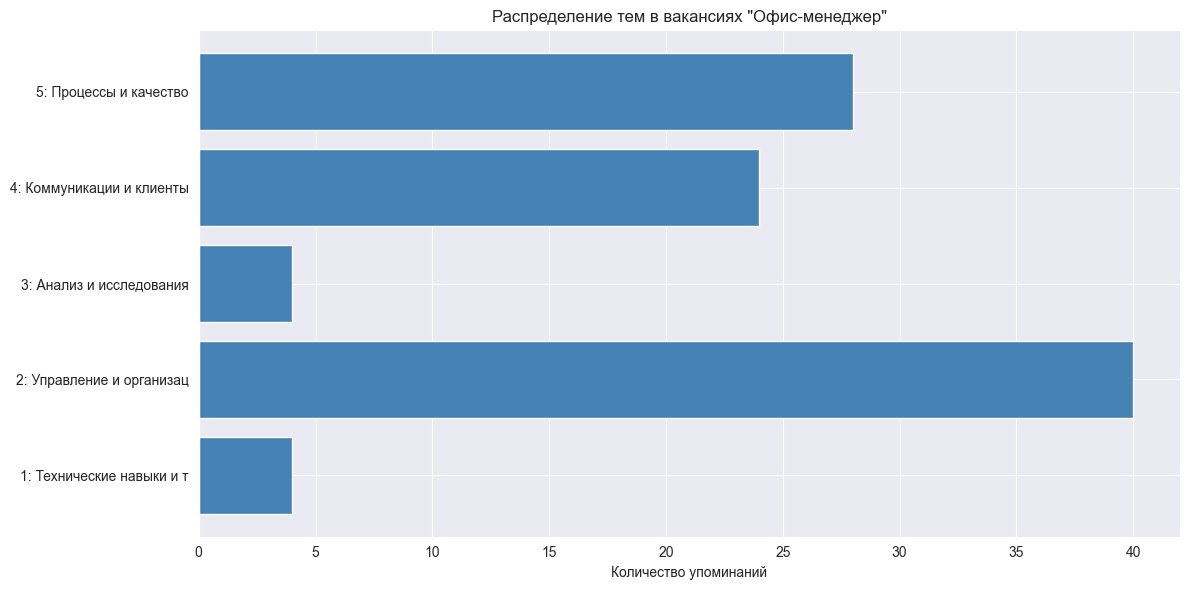

In [10]:
# визуализация распределения тем
plt.figure(figsize=(12, 6))
topics_names = list(topic_scores.keys())
scores = list(topic_scores.values())

# сокращаем названия для графика
short_names = [t.replace('Тема ', '')[:25] for t in topics_names]

plt.barh(range(len(short_names)), scores, color='steelblue')
plt.yticks(range(len(short_names)), short_names)
plt.xlabel('Количество упоминаний')
plt.title(f'Распределение тем в вакансиях "{selected_title}"')
plt.tight_layout()
plt.show()

In [11]:
# анализ n-грамм для более точного выделения тем
print("\n" + "="*60)
print("ТЕМЫ НА ОСНОВЕ БИГРАММ (ДЕТАЛИЗАЦИЯ)")
print("="*60)

# темы с конкретными биграммами
topic_bigrams = {
    'Разработка ПО': ['разработка по', 'программный продукт', 'жизненный цикл', 'написание кода'],
    'Управление проектами': ['управление проектом', 'руководство командой', 'план разработки', 'контроль срок'],
    'Аналитика': ['анализ данных', 'бизнес процесс', 'сбор требование', 'статистический анализ'],
    'Клиентская работа': ['работа клиентом', 'обслуживание клиент', 'поддержка пользователь', 'консультация клиент'],
    'Контроль качества': ['контроль качество', 'тестирование по', 'обеспечение качество', 'проверка код']
}

for topic, bigram_list in topic_bigrams.items():
    count = 0
    for bigram, _ in bigrams.most_common():
        if bigram in bigram_list:
            count += 1
    print(f"{topic}: найдено биграмм: {count}")


ТЕМЫ НА ОСНОВЕ БИГРАММ (ДЕТАЛИЗАЦИЯ)
Разработка ПО: найдено биграмм: 0
Управление проектами: найдено биграмм: 0
Аналитика: найдено биграмм: 0
Клиентская работа: найдено биграмм: 0
Контроль качества: найдено биграмм: 0


In [13]:
# итоговые выводы
print("\n" + "="*60)
print("ВЫВОДЫ ПО РАБОТЕ")
print("="*60)

print(f"""
1. Проанализирована профессия: {selected_title}
   - Всего вакансий: {len(df_selected)}
   - Уникальных слов: {len(freq)}

2. Наиболее частотные слова (указывают на основные требования):
""")

for word, count in freq.most_common(10):
    print(f"   - {word}: {count} упоминаний")

print(f"""
3. Выделено {len(topics)} основных тем:
""")

for topic, keywords in topics.items():
    print(f"   {topic}:")
    print(f"      Ключевые слова: {', '.join(keywords[:5])}...")

print(f"""
4. Самая популярная тема: {max(topic_scores, key=topic_scores.get)}
   - Встречается в {topic_scores[max(topic_scores, key=topic_scores.get)]} вакансиях

5. Самые частотные биграммы (уточняют темы):
""")

for bigram, count in bigrams.most_common(10):
    print(f"   - {bigram}: {count}")

print("""
6. Рекомендации для соискателей:
   - Развивать навыки из наиболее частотных тем
   - Учитывать популярные биграммы при составлении резюме
   - Следить за появлением новых требований в динамике
""")


ВЫВОДЫ ПО РАБОТЕ

1. Проанализирована профессия: Офис-менеджер
   - Всего вакансий: 65
   - Уникальных слов: 2526

2. Наиболее частотные слова (указывают на основные требования):

   - работы: 118 упоминаний
   - компании: 76 упоминаний
   - офиса: 75 упоминаний
   - ведение: 65 упоминаний
   - требования: 57 упоминаний
   - обязанности: 55 упоминаний
   - условия: 53 упоминаний
   - обеспечение: 53 упоминаний
   - организация: 53 упоминаний
   - речь: 49 упоминаний

3. Выделено 5 основных тем:

   Тема 1: Технические навыки и технологии:
      Ключевые слова: программирование, разработка, код, алгоритм, отладка...
   Тема 2: Управление и организация:
      Ключевые слова: управление, руководство, команда, проект, план...
   Тема 3: Анализ и исследования:
      Ключевые слова: анализ, исследование, данные, метрика, статистика...
   Тема 4: Коммуникации и клиенты:
      Ключевые слова: клиент, переговоры, презентация, консультация, поддержка...
   Тема 5: Процессы и качество:
      Клю